# OU and GeoOU: carbon calibration and insurance hedging

Compare no hedging, static hedging and dynamic hedging for PE, TI and EI
portfolios, using the CarbonFund-UL C++ engine. The reference CIR inputs
are those used in the paper experiments, with the corrected mortality
parameter. OU and GeoOU are alternative carbon models calibrated below.

For each factor, match the first two moments of **cumulative carbon**
$A_T=\int_0^T C_t\,dt$. This means matching $E[A_T]$ and
$\mathrm{Var}(A_T)$; it does not mean matching
$\int_0^T E[C_t^2]\,dt$. The third cumulative moment is a diagnostic.

Every input is in the following cells. No preset configuration is loaded.
The default simulation budgets are deliberately small for a first run;
increase them for a convergence study. Each code cell has its own explanation.

Save this notebook in the project root. Select the project's
`.venv-analysis` Python kernel in VS Code. Build the backend once, from
the project root:

```bash
cmake -S . -B build-paper-release -DBoost_ROOT=/usr -DCMAKE_BUILD_TYPE=Release -DCARBONFUND_ENABLE_OPENMP=ON -DBUILD_TESTING=ON
cmake --build build-paper-release --target carbonfund_experiment --parallel
```

**Run controls.** Choose the output name, backend and model list here.
`RUN_SIMULATIONS=False` reloads existing CSVs without needing the executable.
`REUSE_COMPLETED=True` resumes matching completed experiments; it rejects
different simulation inputs. Choose a new `RUN_NAME` for a different experiment.
`OVERWRITE_EXISTING=True` explicitly permits rerunning this output directory.
CIR is always used for calibration diagnostics; its hedging baseline is optional.


In [22]:
from pathlib import Path
from copy import deepcopy
import csv
import json
import math
import sys

SEARCH_START = Path.cwd().resolve()
PROJECT_ROOT = next(
    (p for p in (SEARCH_START, *SEARCH_START.parents)
     if (p / 'include' / 'carbonfund').is_dir()
     and (p / 'python' / 'carbonfund_experiments.py').is_file()), None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError('Open this notebook from the CarbonFund_UL project.')

BINARY = PROJECT_ROOT / 'build-paper-release' / (
    'carbonfund_experiment.exe' if sys.platform == 'win32' else 'carbonfund_experiment'
)
OUTPUT_ROOT = PROJECT_ROOT / 'results' / 'ou_geoou_hedging'
RUN_NAME = 'T20_ou_geoou_02'
SELECTED_MODELS = ['OU', 'GeoOU']
INCLUDE_CIR_BASELINE = False
RUN_SIMULATIONS = True
REUSE_COMPLETED = True
OVERWRITE_EXISTING = False
SHOW_PROGRESS = True
SHOW_FIGURES = True
SAVE_FIGURES = True

sys.path.insert(0, str(PROJECT_ROOT / 'python'))
import numpy as np
import matplotlib.pyplot as plt
from numpy.polynomial.legendre import leggauss
from scipy.integrate import solve_ivp
from scipy.optimize import least_squares
from scipy.stats import norm, t as student_t
from IPython.display import display
import carbonfund_experiments as cfe

if not RUN_NAME or RUN_NAME in ('.', '..') or Path(RUN_NAME).name != RUN_NAME:
    raise ValueError('RUN_NAME must be a single directory name.')
models_to_run = list(SELECTED_MODELS)
if INCLUDE_CIR_BASELINE and 'CIR' not in models_to_run:
    models_to_run.append('CIR')
if (not models_to_run or len(set(models_to_run)) != len(models_to_run)
        or set(models_to_run) - {'OU', 'GeoOU', 'CIR'}):
    raise ValueError('Select distinct models from OU, GeoOU and CIR.')
RUN_DIRECTORY = OUTPUT_ROOT / RUN_NAME
print('Python module:', Path(cfe.__file__).resolve())
print('Models:', models_to_run)
print('Output:', RUN_DIRECTORY)


Python module: /home/edoardolombardo/Documents/codes/CarbonFund_UL/python/carbonfund_experiments.py
Models: ['OU', 'GeoOU']
Output: /home/edoardolombardo/Documents/codes/CarbonFund_UL/results/ou_geoou_hedging/T20_ou_geoou_02


**Market.** The basket has four stocks. Returns, stock volatilities and the
risk-free rate are annual quantities. The covariance matrix is formed from
volatilities and correlations. The same financial inputs are used for all
carbon models. Carbon innovations are independent across factors and from
the stock innovations in the current engine; stock correlations are editable.


In [2]:
market = {
    'risk_free_rate': 0.05,
    'expected_returns': [0.25, 0.15, 0.10, 0.08],
    'volatilities': [0.30, 0.25, 0.20, 0.16],
    'correlations': [
        [1.0000, 0.4397, 0.3900, 0.3168],
        [0.4397, 1.0000, 0.2954, 0.3261],
        [0.3900, 0.2954, 1.0000, 0.3134],
        [0.3168, 0.3261, 0.3134, 1.0000],
    ],
}


**Reference CIR carbon model.** For factor $j$,
$$dC_{j,t}=\kappa_j(\theta_j-C_{j,t})dt+
  \sigma_j\sqrt{C_{j,t}}\,dW_{j,t}.$$
The four vectors below specify $C_0$, $\theta$, $\kappa$ and $\sigma$.
Their units are carbon level, carbon level, inverse years and
square-root carbon per square-root year, respectively.

Automatic calibration here requires strictly positive entries and positive
maturity. Some changed CIR inputs may not admit a GeoOU fit under the chosen
constraints; the solver reports this instead of accepting a poor match.
The optional CIR simulation uses the library's Ninomiya–Victoir scheme,
which requires $\kappa_j\theta_j\ge\sigma_j^2/4$.


In [3]:
reference_cir = {
    'model': 'CIR',
    'initial': [5000.0, 4000.0, 3000.0, 1000.0],
    'long_run_mean': [2500.0, 2000.0, 1500.0, 500.0],
    'mean_reversion': [0.05, 0.05, 0.05, 0.05],
    'volatility': [3.0, 3.0, 3.0, 3.0],
}


**Fund preferences.** `risk_aversion` is the positive risk-aversion
coefficient; `carbon_penalty` is the nonnegative carbon preference.
They determine the four stock allocations and therefore the fund dynamics.
Changing the carbon model changes the allocation path and the fund path.
For OU the allocation rule uses $\max(C_j,0)$; the OU process itself is
not reflected or truncated. Negative-value diagnostics are included below.


In [4]:
fund = {
    'risk_aversion': 1.0,
    'carbon_penalty': 0.0025,
}


**Contract.** Set maturity $T$, initial fund value and guarantee parameters.
The benefit is $g(t,x)=\min(U(t),\max(L(t),x))$, with
$L(t)=L_0e^{g_Lt}$ and $U(t)=U_0e^{g_Ut}$.
PE pays at maturity to survivors; TI pays at death before maturity; EI
combines PE with `endowment_death_benefit_fraction` times TI.
All costs are discounted once to time zero.

**Calibration horizon equals this maturity.** If you change $T$, rerun
calibration and all following cells; the fitted parameters can change.


In [5]:
contract = {
    'fund_value': 1.0,
    'maturity': 20.0,
    'minimum_guarantee': 1.0,
    'maximum_guarantee': 1.0,
    'minimum_guarantee_growth_rate': 0.05,
    'maximum_guarantee_growth_rate': 0.50,
    'endowment_death_benefit_fraction': 1.0,
}


**Mortality.** The Gompertz–Makeham intensity at elapsed time $t$ for
initial age $a$ is
$$\lambda_a(t)=\xi+\frac{1}{b}\exp\left(\frac{a+t-m}{b}\right).$$
`b` is the age scale, not its reciprocal. Lifetimes are independent across
policyholders and independent of the market. The same mortality seeds
are used in each model and contract experiment.


In [6]:
mortality = {
    'xi': 0.0041959,
    'm': 79.6921211,
    'b': 11.5818911,
}


**Portfolios.** Choose which contract types to run and explicitly describe
their age groups, counts and individual notionals. The defaults are
1,000 lives of age 60 with total notional one in each pure portfolio.
You can add groups or change counts and ages independently for each type.
Identical ordered ages and notionals across PE, TI and EI allow the
pathwise check $EI=PE+\rho TI$, where $\rho$ is the EI death fraction.


In [7]:
CONTRACT_TYPES = ['PE', 'TI', 'EI']
population_groups = {
    'PE': [{'count': 1000, 'age': 60.0, 'notional': 0.001}],
    'TI': [{'count': 1000, 'age': 60.0, 'notional': 0.001}],
    'EI': [{'count': 1000, 'age': 60.0, 'notional': 0.001}],
}
if (not CONTRACT_TYPES or len(set(CONTRACT_TYPES)) != len(CONTRACT_TYPES)
        or set(CONTRACT_TYPES) - {'PE', 'TI', 'EI'}):
    raise ValueError('Select distinct contract types from PE, TI and EI.')
populations = {}
for kind in CONTRACT_TYPES:
    populations[kind] = []
    for group in population_groups[kind]:
        if (isinstance(group['count'], bool)
                or not isinstance(group['count'], int) or group['count'] < 1):
            raise ValueError('Each group count must be a positive integer.')
        populations[kind].extend(
            {'type': kind, 'age': group['age'], 'notional': group['notional']}
            for _ in range(group['count'])
        )
    if not populations[kind]:
        raise ValueError(f'{kind}: the portfolio is empty.')
display(cfe.Table([
    {'contract': k, 'lives': len(p), 'total_notional': sum(x['notional'] for x in p)}
    for k, p in populations.items()
]))


contract,lives,total_notional
PE,1000,1
TI,1000,1
EI,1000,1


**Outer scenarios and threads.** `outer_scenarios` is the number of
independent physical market/mortality outcomes. `intervals` sets the
fund/carbon observation, death-settlement and hedge-rebalancing grid.
Death benefits are settled at the next grid endpoint. Increasing this grid
can reduce the discretization error in EI hedging.

`threads=16` requests 16 OpenMP workers; `1` is serial and `0` lets the
backend choose. Rebuild with OpenMP enabled and check `threads_used` below.
`progress_every=20` prints after every 20 completed outer scenarios; it does
not change the simulation or save intermediate CSVs. CSVs are written when
each experiment finishes. The seeds are shared across models: this couples
innovations, **not identical carbon or fund paths across different models**.

These are small workflow budgets. The finer convergence test used `intervals=4160`
and `outer_scenarios=5000`; enter those here when studying convergence.


In [9]:
outer_simulation = {
    'outer_scenarios': 1000,
    'intervals': 256,
    'progress_every': 100,
    'threads': 16,
    'carbon_seed': 2026101801,
    'financial_seed': 2026101802,
    'mortality_seed': 2026101803,
}


**Initial valuation.** Each model/portfolio computes its own premium and
deltas once using these settings, under the library's valuation measure.
`paths` counts actual trajectories: an even antithetic budget of 1,024
uses 512 independent pairs. Odd budgets are rounded up by the current engine.
`intervals` controls the carbon integration grid for valuation.

Available configurations are `standard`, `standard_antithetic`,
`conditioned`, `conditioned_antithetic`. The latter integrates out financial
randomness conditional on carbon. The standard estimator simulates the
complete fund path; there is no marginal-sampling option.
The usual larger initial budget was 4,000 paths and 1,040 intervals.


In [11]:
initial_valuation = {
    'paths': 1024,
    'intervals': 256,
    'configuration': 'conditioned_antithetic',
    'carbon_seed': 2026101804,
    'financial_seed': 2026101805,
}


**Revaluation.** At every intermediate hedge date, surviving liabilities
are revalued with the selected estimator and path count. The remaining grid is
$$N(t)=\max\left(N_{\min},\left\lceil N_{\rm base}
  \frac{T-t}{T}\right\rceil\right).$$
Here `intervals` is $N_{\rm base}$ and `minimum_intervals` is $N_{\min}$,
with $1\le N_{\min}\le N_{\rm base}$. Initial and revaluation seeds are
distinct from outer seeds. The engine creates separate scenario streams,
so thread scheduling does not change the scenario-to-seed assignment.
More inner paths reduce delta estimation noise; a finer outer grid addresses
a different error. The earlier convergence test used 40 paths, base 256 and minimum 4.


In [12]:
revaluation = {
    'paths': 40,
    'intervals': 128,
    'minimum_intervals': 4,
    'configuration': 'conditioned_antithetic',
    'carbon_seed': 2026101806,
    'financial_seed': 2026101807,
}


**Statistical analysis.** `aggregate` reports whole-portfolio costs;
`per_policy` divides by policy count and `per_notional` by total notional.
Raw `hedging.csv` always retains aggregate costs. Summaries include sample
variance, standard deviation, mean SE, Student-$t$ intervals, quantiles and ES.
Positive cost means additional funding is required at time zero.

Mean confidence intervals describe outer sampling uncertainty conditional
on the estimated initial premium. They do not include initial-price
uncertainty or grid bias. A zero-exclusion is therefore not by itself
proof of a systematic bias. Tiny workflow budgets do not estimate tails well.

`comparison_family_size=0` uses three paired strategy contrasts per run;
choose a larger family if desired. Across-model comparisons use the separate
reference and family settings below, and are differences between models,
not accuracy tests of equal theoretical answers. The plotting fields
`bins`, `zoom`, `plot_range` and `title` configure the interface's optional
`result.plot()` method; this notebook's custom figures use `plot_settings`
below. File formats and resolution are shared.


In [13]:
analysis = {
    'normalization': 'aggregate',
    'confidence_level': 0.95,
    'comparison_family_size': 0,
    'quantiles': [0.025, 0.50, 0.90, 0.95, 0.975, 0.99],
    'expected_shortfall_levels': [0.95, 0.99],
    'bins': 70,
    'zoom': None,
    'plot_range': None,
    'figure_formats': ['png', 'pdf'],
    'dpi': 180,
    'title': '',
}
MODEL_COMPARISON_REFERENCE = 'OU'
MODEL_COMPARISON_FAMILY_SIZE = 0
DISPLAY_DIGITS = 5
CHECK_RTOL = 1e-9
CHECK_ATOL = 1e-11
SHOW_COMPLETE_STATISTICS = True
NOTES = (
    'CIR reference; OU and log-OU alternatives fitted to cumulative carbon moments. '
    'Model-specific premiums and deltas. Common innovations across models; '
    'common full market scenarios across contract types within each model. '
    'Time-zero aggregate raw costs; corrected mortality and hedging accounts.'
)


**Calibration settings and optional manual parameters.** OU uses
$a=\kappa$, $b=\theta$ and the same $C_0$. This matches $E[C_t]$ for all
dates. Its constant diffusion $\eta$ is chosen to match $\mathrm{Var}(A_T)$.

GeoOU means $C_t=e^{Y_t}$ with
$dY_t=a(\ell-Y_t)dt+\nu dW_t$. Its stationary level mean is
$e^{\ell+\nu^2/(4a)}$. Impose this mean equal to CIR's $\theta$, so
$$\ell=\log\theta-\frac{\nu^2}{4a}.$$
Fit positive $a,\nu$ to the cumulative mean and variance using deterministic
quadrature and bounded least squares in log parameters. Quadrature is checked
again at a higher order. Fit bounds are numerical search bounds, not additional
economic restrictions. Infeasible targets or insufficient accuracy raise an error.

Use `None` to calibrate automatically. A manual override must contain **all**
vectors, including the initial state and the appropriate long-run mean.
Overrides are diagnosed against CIR but are not forced to match it. They
remain four-factor inputs. All tolerances, fit starts, quadrature orders and
diagnostic dates are visible here. No simulation is used in fitting.


In [14]:
calibration_settings = {
    'quadrature_order': 96,
    'validation_order': 144,
    'third_moment_order': 24,
    'third_moment_validation_order': 40,
    'diagnostic_time_points': 201,
    'ode_method': 'DOP853',
    'ode_rtol': 2e-12,
    'ode_atol': 1e-12,
    'optimizer_ftol': 1e-12,
    'optimizer_xtol': 1e-12,
    'optimizer_gtol': 1e-12,
    'optimizer_max_evaluations': 600,
    'a_bounds': [1e-5, 10.0],
    'nu_bounds': [1e-6, 10.0],
    'a_start_multipliers': [0.5, 1.0, 2.0],
    'nu_start_multiplier': 1.0,
    'moment_relative_tolerance': 1e-7,
    'third_moment_relative_tolerance': 1e-5,
}
manual_carbon_parameters = {
    'OU': None,
    'GeoOU': None,
    # Example OU replacement (diffusions have carbon-level units):
    # 'OU': {'model': 'OU', 'initial': [5000., 4000., 3000., 1000.],
    #        'long_run_mean': [2500., 2000., 1500., 500.],
    #        'mean_reversion': [.05, .05, .05, .05],
    #        'volatility': [199., 178., 154., 89.]},
    # GeoOU replacement keys: model, initial, long_run_log_mean,
    # mean_reversion, volatility. All four vectors must be supplied.
}


**Figure settings.** Choose colors, bins, axis ranges, legend placement,
zoom and formats here. Strategy colors use MATLAB's blue, orange and yellow;
histogram edges are black. Quantiles change the displayed horizontal range,
not the saved observations or statistical summaries. The plotted density
always divides by the full sample count, even when tails are outside the view.
Set `show_zoom=False` to remove insets, or `SHOW_FIGURES=False` to suppress
inline displays. `SAVE_FIGURES` independently controls file export.


In [15]:
plot_settings = {
    'model_colors': {'CIR': '#202020', 'OU': '#0072BD', 'GeoOU': '#D95319'},
    'strategy_colors': {
        'no_hedge': '#0072BD', 'static_hedge': '#D95319', 'dynamic_hedge': '#EDB120',
    },
    'strategy_labels': {
        'no_hedge': 'No hedging', 'static_hedge': 'Static hedging',
        'dynamic_hedge': 'Dynamic hedging',
    },
    'density_bins': 80,
    'strategy_quantiles': {
        'no_hedge': [0.0, 1.0], 'static_hedge': [0.0, 1.0],
        'dynamic_hedge': [0.0, 1.0],
    },
    'dynamic_model_quantiles': [0.0, 1.0],
    'show_zoom': True,
    'zoom_quantiles': [0.01, 0.99],
    'zoom_position': [0.53, 0.43, 0.43, 0.50],
    'legend_location': 'best',
    'show_titles': True,
    'font_size': 11,
    'histogram_alpha': 0.45,
    'edge_color': 'black',
    'edge_linewidth': 0.45,
    'grid_alpha': 0.2,
    'carbon_figure_size': [17, 7],
    'cost_figure_size': [10, 5.5],
    'range_padding_fraction': 0.02,
    'zero_width_fallback_fraction': 0.05,
}


**Moment calculations.** The functions below implement deterministic
means and covariance kernels. Cumulative variance is integrated over the
ordered triangle $0\le s\le t\le T$ and multiplied by two; this avoids a
covariance kink on a rectangular grid. CIR's first three cumulative
cumulants are obtained from derivatives of its affine-transform Riccati ODE
and cross-checked with independent mean/covariance quadrature.

OU has Gaussian $A_T$, so its third central moment is zero. For GeoOU,
joint lognormal moments provide the third central moment; ordered triple
quadrature is evaluated at two orders to check accuracy. These calculations
concern the continuous models. A finite simulation grid introduces a
separate integration/discretization error.


In [16]:
def positive_vector(values, label):
    x = np.asarray(values, dtype=float)
    if x.shape != (4,) or not np.all(np.isfinite(x)) or np.any(x <= 0):
        raise ValueError(f'{label} must contain four finite positive entries.')
    return x

def unit_rule(order):
    if isinstance(order, bool) or not isinstance(order, int) or order < 2:
        raise ValueError('Quadrature orders must be integers >= 2.')
    nodes, weights = leggauss(order)
    return (nodes + 1.0) / 2.0, weights / 2.0

def decay_integral(a, t):
    t = np.asarray(t, dtype=float)
    return t if a == 0.0 else -np.expm1(-a * t) / a

def marginal_moments(model, c0, mean, a, vol, t):
    t = np.asarray(t, dtype=float)
    e = np.exp(-a * t)
    if model == 'GeoOU':
        vy = vol**2 * decay_integral(2.0 * a, t)
        m = np.exp(mean + (np.log(c0) - mean) * e + 0.5 * vy)
        v = m**2 * np.expm1(vy)
        third = m**3 * (np.exp(vy) + 2.0) * np.expm1(vy)**2
    else:
        m = mean + (c0 - mean) * e
        if model == 'OU':
            v = vol**2 * decay_integral(2.0 * a, t)
            third = np.zeros_like(t)
        elif model == 'CIR':
            if a == 0.0:
                v = vol**2 * c0 * t
                third = 1.5 * c0 * vol**4 * t**2
            else:
                one_minus_e = -np.expm1(-a * t)
                v = vol**2 / a * (
                    c0 * e * one_minus_e + 0.5 * mean * one_minus_e**2
                )
                third = vol**4 / (2.0 * a**2) * (
                    mean * one_minus_e**3 + 3.0 * c0 * e * one_minus_e**2
                )
        else:
            raise ValueError(model)
    return m, v, third

def carbon_covariance(model, c0, mean, a, vol, s, t):
    ms, vs, _ = marginal_moments(model, c0, mean, a, vol, s)
    decay = np.exp(-a * (t - s))
    if model != 'GeoOU':
        return vs * decay
    mt, _, _ = marginal_moments(model, c0, mean, a, vol, t)
    log_cov = vol**2 * decay_integral(2.0 * a, s) * decay
    return ms * mt * np.expm1(log_cov)

def cumulative_mean_variance(model, c0, mean, a, vol, T, order):
    x, w = unit_rule(order)
    s = T * x
    t = s[:, None] + (T - s[:, None]) * x[None, :]
    mt, _, _ = marginal_moments(model, c0, mean, a, vol, s)
    cumulative_mean = T * np.dot(w, mt)
    cov = carbon_covariance(model, c0, mean, a, vol, s[:, None], t)
    cumulative_variance = 2.0 * np.sum(
        (T * w)[:, None] * (T - s[:, None]) * w[None, :] * cov
    )
    return np.array([cumulative_mean, cumulative_variance], dtype=float)

def cir_cumulative_cumulants(c0, theta, kappa, sigma, T):
    # Normalize carbon by theta to improve the ODE scale.
    relative_initial = c0 / theta
    relative_sigma_squared = sigma**2 / theta

    def rhs(time, y):
        b1, b2, b3, a1, a2, a3 = y
        return [
            1.0 - kappa * b1,
            -kappa * b2 + relative_sigma_squared * b1**2,
            -kappa * b3 + 3.0 * relative_sigma_squared * b1 * b2,
            kappa * b1, kappa * b2, kappa * b3,
        ]

    sol = solve_ivp(
        rhs, (0.0, T), np.zeros(6), method=calibration_settings['ode_method'],
        rtol=calibration_settings['ode_rtol'], atol=calibration_settings['ode_atol'],
    )
    if not sol.success:
        raise RuntimeError('CIR moment ODE failed: ' + sol.message)
    y = sol.y[:, -1]
    return (y[3:] + relative_initial * y[:3]) * np.array([theta, theta**2, theta**3])

def geoou_cumulative_third(c0, ell, a, nu, T, order):
    # Ordered simplex 0 < s < t < u < T, multiplied by 3!.
    x, w = unit_rule(order)
    s = (T * x)[:, None, None]
    t = s + (T - s) * x[None, :, None]
    u = t + (T - t) * x[None, None, :]
    ms, _, _ = marginal_moments('GeoOU', c0, ell, a, nu, s)
    mt, _, _ = marginal_moments('GeoOU', c0, ell, a, nu, t)
    mu, _, _ = marginal_moments('GeoOU', c0, ell, a, nu, u)
    vs = nu**2 * decay_integral(2.0 * a, s)
    vt = nu**2 * decay_integral(2.0 * a, t)
    xst = np.expm1(vs * np.exp(-a * (t - s)))
    xsu = np.expm1(vs * np.exp(-a * (u - s)))
    xtu = np.expm1(vt * np.exp(-a * (u - t)))
    central = ms * mt * mu * (xst*xsu + xst*xtu + xsu*xtu + xst*xsu*xtu)
    weights = (T * w)[:, None, None] * w[None, :, None] * w[None, None, :]
    return float(6.0 * np.sum(weights * (T - s) * (T - t) * central))

def factor_parameters(carbon, j):
    mean_key = 'long_run_log_mean' if carbon['model'] == 'GeoOU' else 'long_run_mean'
    return (carbon['initial'][j], carbon[mean_key][j],
            carbon['mean_reversion'][j], carbon['volatility'][j])

T = float(contract['maturity'])
if not np.isfinite(T) or T <= 0:
    raise ValueError('Maturity must be finite and positive.')
c0 = positive_vector(reference_cir['initial'], 'CIR initial')
theta = positive_vector(reference_cir['long_run_mean'], 'CIR long_run_mean')
kappa = positive_vector(reference_cir['mean_reversion'], 'CIR mean_reversion')
sigma = positive_vector(reference_cir['volatility'], 'CIR volatility')
if reference_cir['model'] != 'CIR':
    raise ValueError('reference_cir.model must be CIR.')
if calibration_settings['validation_order'] <= calibration_settings['quadrature_order']:
    raise ValueError('Use a higher validation quadrature order than the fit order.')
if calibration_settings['third_moment_validation_order'] <= calibration_settings['third_moment_order']:
    raise ValueError('Use a higher validation order for the third moment.')
if (not isinstance(calibration_settings['diagnostic_time_points'], int)
        or calibration_settings['diagnostic_time_points'] < 2):
    raise ValueError('diagnostic_time_points must be an integer >= 2.')
print('Moment functions ready; calibration horizon:', T, 'years')


Moment functions ready; calibration horizon: 20.0 years


**Compute the fitted parameters.** OU's cumulative variance coefficient is
evaluated as a positive integral,
$$\mathrm{Var}(A_T)=\eta^2\int_0^T
  \left(\frac{1-e^{-\kappa(T-s)}}{\kappa}\right)^2ds.$$
GeoOU then solves the two cumulative moment conditions under the stationary
mean constraint. Output distinguishes automatically fitted and manually
supplied models. Changing a manual input does not recalibrate it silently.
All derived vectors are saved later as actual simulation inputs.


In [17]:
fit_order = calibration_settings['quadrature_order']
validation_order = calibration_settings['validation_order']
moment_tol = calibration_settings['moment_relative_tolerance']
if not 0 < moment_tol < 1:
    raise ValueError('moment_relative_tolerance must lie in (0, 1).')
targets = np.array([
    cir_cumulative_cumulants(c0[j], theta[j], kappa[j], sigma[j], T)
    for j in range(4)
])
for j in range(4):
    direct = cumulative_mean_variance('CIR', c0[j], theta[j], kappa[j], sigma[j], T, validation_order)
    if np.max(np.abs(direct / targets[j, :2] - 1.0)) > moment_tol:
        raise RuntimeError(f'Factor {j + 1}: CIR ODE/quadrature disagreement.')

carbon_models = {'CIR': deepcopy(reference_cir)}
calibration_status = {'CIR': 'reference'}
optimizer_records = []
x, w = unit_rule(validation_order)
eta = np.array([
    math.sqrt(targets[j, 1] / (T * np.dot(w, decay_integral(kappa[j], T * (1-x))**2)))
    for j in range(4)
])
carbon_models['OU'] = {
    'model': 'OU', 'initial': c0.tolist(), 'long_run_mean': theta.tolist(),
    'mean_reversion': kappa.tolist(), 'volatility': eta.tolist(),
}
calibration_status['OU'] = 'automatic'
if manual_carbon_parameters.get('OU') is not None:
    carbon_models['OU'] = deepcopy(manual_carbon_parameters['OU'])
    calibration_status['OU'] = 'manual'

if manual_carbon_parameters.get('GeoOU') is not None:
    carbon_models['GeoOU'] = deepcopy(manual_carbon_parameters['GeoOU'])
    calibration_status['GeoOU'] = 'manual'
else:
    fitted_a, fitted_ell, fitted_nu = [], [], []
    lower = np.array([calibration_settings['a_bounds'][0], calibration_settings['nu_bounds'][0]])
    upper = np.array([calibration_settings['a_bounds'][1], calibration_settings['nu_bounds'][1]])
    if (np.any(lower <= 0) or np.any(upper <= lower)
            or not np.all(np.isfinite([lower, upper]))):
        raise ValueError('Fit bounds must be finite, positive and ordered.')
    starts = calibration_settings['a_start_multipliers']
    if (not starts or any(x <= 0 or not np.isfinite(x) for x in starts)
            or calibration_settings['nu_start_multiplier'] <= 0):
        raise ValueError('Fit start multipliers must be positive.')
    for j in range(4):
        scaled_target = targets[j, :2] / np.array([theta[j], theta[j]**2])

        def residual(z, order=fit_order):
            a, nu = np.exp(z)
            ell_relative = -nu**2 / (4.0 * a)
            fitted = cumulative_mean_variance(
                'GeoOU', c0[j] / theta[j], ell_relative, a, nu, T, order,
            )
            with np.errstate(divide='raise', invalid='raise', over='raise'):
                return np.log(fitted / scaled_target)

        candidates = []
        for multiplier in starts:
            guess = np.array([
                kappa[j] * multiplier,
                sigma[j] / math.sqrt(c0[j]) * calibration_settings['nu_start_multiplier'],
            ])
            z0 = np.maximum(np.log(lower), np.minimum(np.log(upper), np.log(guess)))
            candidate = least_squares(
                residual, z0, bounds=(np.log(lower), np.log(upper)),
                ftol=calibration_settings['optimizer_ftol'],
                xtol=calibration_settings['optimizer_xtol'],
                gtol=calibration_settings['optimizer_gtol'],
                max_nfev=calibration_settings['optimizer_max_evaluations'],
            )
            candidates.append(candidate)
        best = min(candidates, key=lambda s: float(np.max(np.abs(s.fun))))
        a, nu = np.exp(best.x)
        relative_error = float(np.max(np.abs(np.expm1(residual(best.x, validation_order)))))
        if not best.success or not np.isfinite(relative_error) or relative_error > moment_tol:
            raise RuntimeError(
                f'Factor {j + 1}: no adequate GeoOU match under these constraints/bounds. '
                f'Maximum relative moment error={relative_error:.3g}. '
                'Review the target, fit bounds/accuracy or provide manual parameters.'
            )
        ell = math.log(theta[j]) - nu**2 / (4.0 * a)
        fitted_a.append(float(a)); fitted_ell.append(float(ell)); fitted_nu.append(float(nu))
        optimizer_records.append({
            'factor': j + 1, 'evaluations': int(best.nfev),
            'relative_moment_error': relative_error,
            'message': str(best.message),
        })
    carbon_models['GeoOU'] = {
        'model': 'GeoOU', 'initial': c0.tolist(), 'long_run_log_mean': fitted_ell,
        'mean_reversion': fitted_a, 'volatility': fitted_nu,
    }
    calibration_status['GeoOU'] = 'automatic'

# Validate manual vectors and model identity before computing diagnostics.
for model, carbon in carbon_models.items():
    mean_key = 'long_run_log_mean' if model == 'GeoOU' else 'long_run_mean'
    expected_keys = {'model', 'initial', mean_key, 'mean_reversion', 'volatility'}
    if carbon.get('model') != model or set(carbon) != expected_keys:
        raise ValueError(f'{model}: provide exactly the full parameter dictionary.')
    for key in expected_keys - {'model'}:
        arr = np.asarray(carbon[key], dtype=float)
        if arr.shape != (4,) or not np.all(np.isfinite(arr)):
            raise ValueError(f'{model}.{key}: four finite entries are required.')
    if np.any(np.array(carbon['mean_reversion']) < 0) or np.any(np.array(carbon['volatility']) < 0):
        raise ValueError(f'{model}: mean reversion and volatility must be nonnegative.')
    if model == 'GeoOU' and np.any(np.array(carbon['initial']) <= 0):
        raise ValueError('GeoOU initial levels must be positive.')

parameter_rows = []
for model in ('CIR', 'OU', 'GeoOU'):
    carbon = carbon_models[model]
    for j in range(4):
        initial, mean, a, vol = factor_parameters(carbon, j)
        stationary_mean = math.exp(mean + vol**2/(4*a)) if model == 'GeoOU' and a > 0 else (
            mean if model != 'GeoOU' and a > 0 else None
        )
        parameter_rows.append({
            'model': model, 'factor': j + 1, 'source': calibration_status[model],
            'initial': initial, 'mean_reversion': a, 'volatility': vol,
            'long_run_mean': mean if model != 'GeoOU' else None,
            'long_run_log_mean': mean if model == 'GeoOU' else None,
            'stationary_level_mean': stationary_mean,
        })
display(cfe.Table(parameter_rows))


model,factor,source,initial,mean_reversion,volatility,long_run_mean,long_run_log_mean,stationary_level_mean
CIR,1,reference,5000,0.05,3,2500,None,2500
CIR,2,reference,4000,0.05,3,2000,None,2000
CIR,3,reference,3000,0.05,3,1500,None,1500
CIR,4,reference,1000,0.05,3,500,None,500
OU,1,automatic,5000,0.05,199.3860657,2500,None,2500
OU,2,automatic,4000,0.05,178.3363186,2000,None,2000
OU,3,automatic,3000,0.05,154.4437823,1500,None,1500
OU,4,automatic,1000,0.05,89.16815931,500,None,500
GeoOU,1,automatic,5000,0.03896581836,0.04730537416,None,7.809688566,2500
GeoOU,2,automatic,4000,0.03912637259,0.05290451237,None,7.583018822,2000


**Check what was matched and what was not.** The first table reports the
mean, variance and skewness of $A_T$, plus moment errors against CIR.
Automatic OU and GeoOU fits must pass the chosen tolerance. Manual inputs
may have nonzero errors. The second table compares marginal mean and
variance curves and OU negative-level probabilities.

Matching two cumulative moments does not match the entire carbon law,
nonlinear fund allocations, prices or hedging costs. OU has zero cumulative
skewness. For positively correlated lognormal levels, GeoOU satisfies
$$E[(A_T-E[A_T])^3]\ge
  \frac{3\,\mathrm{Var}(A_T)^2}{E[A_T]}.$$
This bound follows by expanding the three-way lognormal central moment and
applying the weighted Cauchy–Schwarz inequality. Its corresponding skewness
lower bound is $3\sqrt{\mathrm{Var}(A_T)}/E[A_T]$. The CIR targets below
lie below that bound for the supplied inputs, so exact matching of all three
cumulative moments with this GeoOU is impossible. The notebook does not
try to force that match.

`expected_fraction_time_negative` is the time-average of the marginal
probability $P(C_t<0)$, **not** the probability of ever crossing zero.
Positive-part carbon used in OU allocations has different cumulative moments
from the untruncated OU calibrated here.


In [18]:
diagnostic_times = np.linspace(0.0, T, calibration_settings['diagnostic_time_points'])
integral_rows, marginal_rows, curve_rows = [], [], []
x_occ, w_occ = unit_rule(validation_order)
for model in ('CIR', 'OU', 'GeoOU'):
    for j in range(4):
        p = factor_parameters(carbon_models[model], j)
        mean_a, variance_a = cumulative_mean_variance(model, *p, T, validation_order)
        base_check = cumulative_mean_variance(model, *p, T, fit_order)
        scales = np.maximum(np.abs([mean_a, variance_a]), np.finfo(float).tiny)
        quadrature_error = float(np.max(np.abs(base_check - [mean_a, variance_a]) / scales))
        if quadrature_error > moment_tol:
            raise RuntimeError(f'{model} factor {j + 1}: increase quadrature orders.')
        if model == 'CIR':
            third = targets[j, 2]
            third_error = 0.0
        elif model == 'OU':
            third = third_error = 0.0
        else:
            third_low = geoou_cumulative_third(*p, T, calibration_settings['third_moment_order'])
            third = geoou_cumulative_third(*p, T, calibration_settings['third_moment_validation_order'])
            third_error = abs(third_low - third) / abs(third) if third != 0 else abs(third_low)
            if third_error > calibration_settings['third_moment_relative_tolerance']:
                raise RuntimeError(f'GeoOU factor {j + 1}: increase third-moment quadrature orders.')
        skew = third / variance_a**1.5 if variance_a > 0 else 0.0
        matching_error = np.array([mean_a, variance_a]) / targets[j, :2] - 1.0
        if calibration_status[model] == 'automatic' and np.max(np.abs(matching_error)) > moment_tol:
            raise RuntimeError(f'{model} factor {j + 1}: calibrated moment tolerance failed.')
        integral_rows.append({
            'model': model, 'factor': j + 1, 'horizon': T,
            'mean_integral': float(mean_a), 'variance_integral': float(variance_a),
            'std_integral': math.sqrt(variance_a), 'third_central_integral': float(third),
            'skewness_integral': float(skew),
            'relative_mean_error_vs_CIR': float(matching_error[0]),
            'relative_variance_error_vs_CIR': float(matching_error[1]),
            'GeoOU_skew_lower_bound_at_these_moments': float(3*math.sqrt(variance_a)/mean_a) if mean_a > 0 else None,
            'mean_variance_quadrature_relative_change': quadrature_error,
            'third_moment_quadrature_relative_change': float(third_error),
        })
        m, v, third_t = marginal_moments(model, *p, diagnostic_times)
        sd = np.sqrt(v)
        negative = np.zeros_like(m)
        occupation = 0.0
        if model == 'OU':
            negative[sd > 0] = norm.cdf(-m[sd > 0] / sd[sd > 0])
            negative[sd == 0] = (m[sd == 0] < 0).astype(float)
            mo, vo, _ = marginal_moments(model, *p, T * x_occ)
            po = (mo < 0).astype(float)
            np.divide(-mo, np.sqrt(vo), out=po, where=vo > 0)
            po[vo > 0] = norm.cdf(po[vo > 0])
            occupation = float(w_occ @ po)
        ref_mean, ref_var, _ = marginal_moments('CIR', *factor_parameters(reference_cir, j), diagnostic_times)
        valid_var = ref_var > 0
        curve_rows.append({
            'model': model, 'factor': j + 1,
            'max_relative_mean_curve_error_vs_CIR': float(np.max(np.abs(m/ref_mean - 1))),
            'max_relative_variance_curve_error_vs_CIR': float(np.max(np.abs(v[valid_var]/ref_var[valid_var] - 1))),
            'probability_negative_at_T': float(negative[-1]),
            'max_marginal_probability_negative': float(np.max(negative)),
            'expected_fraction_time_negative': occupation,
        })
        for i, time in enumerate(diagnostic_times):
            marginal_rows.append({
                'model': model, 'factor': j + 1, 'time': float(time),
                'mean': float(m[i]), 'variance': float(v[i]), 'std': float(sd[i]),
                'third_central_moment': float(third_t[i]),
                'probability_negative': float(negative[i]),
            })
display(cfe.Table(integral_rows))
display(cfe.Table(curve_rows))
print('All automatic fits and quadrature checks passed.')


model,factor,horizon,mean_integral,variance_integral,std_integral,third_central_integral,skewness_integral,relative_mean_error_vs_CIR,relative_variance_error_vs_CIR,GeoOU_skew_lower_bound_at_these_moments,mean_variance_quadrature_relative_change,third_moment_quadrature_relative_change
CIR,1,20,81606.02794,53459473.53,7311.598562,7.402950453e+10,0.1893947021,-2.220446049e-16,5.551115123e-15,0.2687889147,1.114950089e-15,0
CIR,2,20,65284.82235,42767578.82,6539.692563,5.922360362e+10,0.2117497143,-3.330669074e-16,5.773159728e-15,0.3005151425,1.21947666e-15,0
CIR,3,20,48963.61676,32075684.12,5663.539893,4.441770272e+10,0.2445075091,-1.110223025e-16,5.107025913e-15,0.3470049968,1.277546977e-15,0
CIR,4,20,16321.20559,10691894.71,3269.846282,1.480590091e+10,0.4234994286,-2.220446049e-16,4.440892099e-15,0.6010302849,1.21947666e-15,0
OU,1,20,81606.02794,53459473.53,7311.598562,0,0,-2.220446049e-16,5.329070518e-15,0.2687889147,1.114950089e-15,0
OU,2,20,65284.82235,42767578.82,6539.692563,0,0,-3.330669074e-16,5.329070518e-15,0.3005151425,1.045265709e-15,0
OU,3,20,48963.61676,32075684.12,5663.539893,0,0,-1.110223025e-16,5.551115123e-15,0.3470049968,1.277546977e-15,0
OU,4,20,16321.20559,10691894.71,3269.846282,0,0,-2.220446049e-16,5.329070518e-15,0.6010302849,1.21947666e-15,0
GeoOU,1,20,81606.02794,53459473.53,7311.598562,1.234941956e+11,0.315943576,6.661338148e-16,2.220446049e-15,0.2687889147,1.672425134e-15,2.965410121e-15
GeoOU,2,20,65284.82235,42767578.82,6539.692563,9.889697766e+10,0.3535989957,-2.220446049e-16,8.881784197e-16,0.3005151425,1.21947666e-15,3.085794819e-15


model,factor,max_relative_mean_curve_error_vs_CIR,max_relative_variance_curve_error_vs_CIR,probability_negative_at_T,max_marginal_probability_negative,expected_fraction_time_negative
CIR,1,0,0,0,0,0
CIR,2,0,0,0,0,0
CIR,3,0,0,0,0,0
CIR,4,0,0,0,0,0
OU,1,0,0.1489042547,2.72698429e-09,2.72698429e-09,1.615723457e-10
OU,2,0,0.1489042547,9.096154064e-08,9.096154064e-08,6.521110432e-09
OU,3,0,0.1489042547,3.121545472e-06,3.121545472e-06,2.836820296e-07
OU,4,0,0.1489042547,0.004547534048,0.004547534048,0.0009157675211
GeoOU,1,0.00829757117,0.2397253077,0,0,0
GeoOU,2,0.008150339875,0.2404737457,0,0,0


All automatic fits and quadrature checks passed.


**Carbon mean and standard-deviation curves.** Plot the continuous-model
marginal moments before running hedging. CIR remains in these diagnostics
even when its hedging baseline is disabled. The curves make visible the
differences that cumulative moment matching does not eliminate. Figure
export is deferred until the output directory has been checked below.


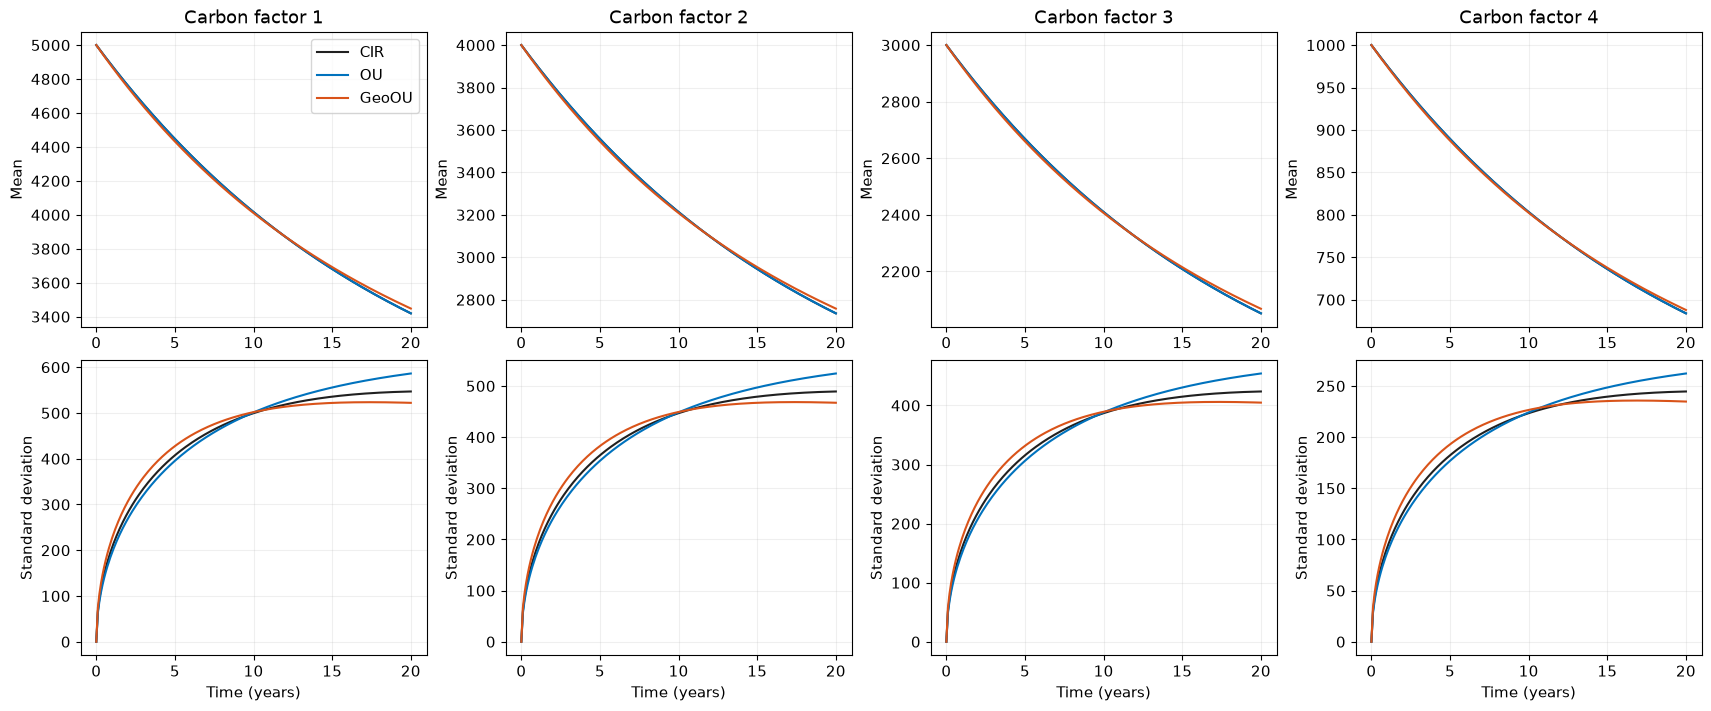

In [19]:
plt.rcParams.update({'font.size': plot_settings['font_size']})
carbon_figure, axes = plt.subplots(2, 4, figsize=plot_settings['carbon_figure_size'], constrained_layout=True)
for j in range(4):
    for model in ('CIR', 'OU', 'GeoOU'):
        m, v, _ = marginal_moments(model, *factor_parameters(carbon_models[model], j), diagnostic_times)
        color = plot_settings['model_colors'][model]
        axes[0, j].plot(diagnostic_times, m, color=color, label=model)
        axes[1, j].plot(diagnostic_times, np.sqrt(v), color=color, label=model)
    if plot_settings['show_titles']:
        axes[0, j].set_title(f'Carbon factor {j + 1}')
    axes[1, j].set_xlabel('Time (years)')
    axes[0, j].set_ylabel('Mean')
    axes[1, j].set_ylabel('Standard deviation')
    for ax in axes[:, j]:
        ax.grid(alpha=plot_settings['grid_alpha'])
axes[0, 0].legend(loc=plot_settings['legend_location'])
if SHOW_FIGURES:
    display(carbon_figure)
plt.close(carbon_figure)


**Assemble and validate all experiments.** Each chosen carbon model receives
the same financial, mortality, contract and numerical settings. Premiums
and deltas are computed separately, not copied from CIR. PE/TI/EI share
complete market scenarios within each model, since market settings and seeds
agree. Across models, only innovation streams and initial reference inputs
are coupled; no claim is made that fund paths are equal.

Configuration dictionaries are snapshots: after editing an input, rerun
calibration and assembly, then the following cells. The preview lists every
experiment's budget. The JSON below contains **all chosen inputs**, actual
fitted model parameters and diagnostic settings; it is saved with the run.


In [20]:
if MODEL_COMPARISON_REFERENCE not in models_to_run:
    raise ValueError('MODEL_COMPARISON_REFERENCE must be one of the models being run.')
configs = {}
for model in models_to_run:
    configs[model] = {}
    for kind in CONTRACT_TYPES:
        cfg = {
            'schema_version': 1, 'experiment': 'hedging',
            'market': deepcopy(market), 'carbon': deepcopy(carbon_models[model]),
            'fund': deepcopy(fund), 'contract': deepcopy(contract),
            'mortality': deepcopy(mortality), 'population': deepcopy(populations[kind]),
            'hedging': {**deepcopy(outer_simulation),
                        'initial': deepcopy(initial_valuation),
                        'revaluation': deepcopy(revaluation)},
            'analysis': deepcopy(analysis), 'notes': NOTES,
        }
        cfe.validate_config(cfg)
        configs[model][kind] = cfg

def simulation_inputs(cfg):
    result = deepcopy({k: v for k, v in cfg.items() if k not in ('analysis', 'notes')})
    result['hedging']['revaluation'].setdefault('minimum_intervals', 1)
    return result

experiment_design = {
    'schema_version': 1,
    'reference_cir': deepcopy(reference_cir),
    'calibration_horizon': T,
    'calibration_settings': deepcopy(calibration_settings),
    'manual_carbon_parameters': deepcopy(manual_carbon_parameters),
    'carbon_models': deepcopy(carbon_models),
    'models_to_run': list(models_to_run), 'contract_types': list(CONTRACT_TYPES),
    'population_groups': deepcopy(population_groups),
    'simulation_inputs': {
        model: {kind: simulation_inputs(cfg) for kind, cfg in by_kind.items()}
        for model, by_kind in configs.items()
    },
}
display(cfe.Table([
    {'model': model, 'contract': kind, 'outer_scenarios': cfg['hedging']['outer_scenarios'],
     'outer_intervals': cfg['hedging']['intervals'],
     'initial_paths': cfg['hedging']['initial']['paths'],
     'initial_intervals': cfg['hedging']['initial']['intervals'],
     'revaluation_paths': cfg['hedging']['revaluation']['paths'],
     'revaluation_intervals': cfg['hedging']['revaluation']['intervals'],
     'minimum_intervals': cfg['hedging']['revaluation']['minimum_intervals'],
     'threads_requested': cfg['hedging']['threads']}
    for model, by_kind in configs.items() for kind, cfg in by_kind.items()
]))
print(json.dumps({
    'market': market, 'reference_cir': reference_cir, 'carbon_models': carbon_models,
    'fund': fund, 'contract': contract, 'mortality': mortality,
    'population_groups': population_groups, 'outer_simulation': outer_simulation,
    'initial_valuation': initial_valuation, 'revaluation': revaluation,
    'analysis': analysis, 'calibration_settings': calibration_settings,
}, indent=2, allow_nan=False))


model,contract,outer_scenarios,outer_intervals,initial_paths,initial_intervals,revaluation_paths,revaluation_intervals,minimum_intervals,threads_requested
OU,PE,1000,256,1024,256,40,128,4,16
OU,TI,1000,256,1024,256,40,128,4,16
OU,EI,1000,256,1024,256,40,128,4,16
GeoOU,PE,1000,256,1024,256,40,128,4,16
GeoOU,TI,1000,256,1024,256,40,128,4,16
GeoOU,EI,1000,256,1024,256,40,128,4,16


{
  "market": {
    "risk_free_rate": 0.05,
    "expected_returns": [
      0.25,
      0.15,
      0.1,
      0.08
    ],
    "volatilities": [
      0.3,
      0.25,
      0.2,
      0.16
    ],
    "correlations": [
      [
        1.0,
        0.4397,
        0.39,
        0.3168
      ],
      [
        0.4397,
        1.0,
        0.2954,
        0.3261
      ],
      [
        0.39,
        0.2954,
        1.0,
        0.3134
      ],
      [
        0.3168,
        0.3261,
        0.3134,
        1.0
      ]
    ]
  },
  "reference_cir": {
    "model": "CIR",
    "initial": [
      5000.0,
      4000.0,
      3000.0,
      1000.0
    ],
    "long_run_mean": [
      2500.0,
      2000.0,
      1500.0,
      500.0
    ],
    "mean_reversion": [
      0.05,
      0.05,
      0.05,
      0.05
    ],
    "volatility": [
      3.0,
      3.0,
      3.0,
      3.0
    ]
  },
  "carbon_models": {
    "CIR": {
      "model": "CIR",
      "initial": [
        5000.0,
        4000.0,
    

**Run, resume or reload, and save the calibration.** The output manifest
prevents accidental reuse of a directory with a different experimental
design. A completed run is reused only if its simulation inputs match.
Changing analysis/figure settings permits reanalysis of existing CSVs;
it does not require repeating C++ simulations.

Each model/contract run writes its raw scenario CSV, exact configuration,
metadata and console log. The root directory also stores all fitted
parameters, moment diagnostics, the complete experiment design and current
analysis settings. Computation stays in C++; Python configures and analyses.


In [23]:
def write_rows(path, rows):
    if not rows:
        return
    with Path(path).open('w', newline='', encoding='utf-8') as stream:
        writer = csv.DictWriter(stream, fieldnames=list(rows[0]))
        writer.writeheader()
        writer.writerows(rows)

def write_json(path, value):
    Path(path).write_text(json.dumps(value, indent=2, allow_nan=False) + '\n', encoding='utf-8')

manifest_path = RUN_DIRECTORY / 'experiment_design.json'
# Round-trip canonical JSON handles numeric arrays and key order consistently.
design_json = json.loads(json.dumps(experiment_design, allow_nan=False))
if manifest_path.exists():
    saved_design = json.loads(manifest_path.read_text(encoding='utf-8'))
    if saved_design != design_json and not (RUN_SIMULATIONS and OVERWRITE_EXISTING):
        raise ValueError('This RUN_NAME contains a different design. Choose a new RUN_NAME.')
elif RUN_DIRECTORY.exists() and any(RUN_DIRECTORY.iterdir()):
    if not (RUN_SIMULATIONS and OVERWRITE_EXISTING):
        raise ValueError('Nonempty output directory has no design manifest. Choose a new RUN_NAME.')

# Check every existing configuration before writing root-level outputs.
plan = []
for model, by_kind in configs.items():
    for kind, cfg in by_kind.items():
        destination = RUN_DIRECTORY / model / kind
        complete = all((destination / name).is_file() for name in ('config.json', 'metadata.json', 'hedging.csv'))
        existing = cfe.load_result(destination) if complete else None
        # Compare the original Python-written input, avoiding a second
        # floating-point serialization round-trip through C++ metadata.
        saved_input = json.loads((destination / 'config.json').read_text(encoding='utf-8')) if complete else None
        if existing is not None and simulation_inputs(saved_input) != simulation_inputs(cfg):
            if not (RUN_SIMULATIONS and OVERWRITE_EXISTING):
                raise ValueError(f'{model}/{kind}: saved simulation inputs differ.')
        if not RUN_SIMULATIONS and existing is None:
            raise FileNotFoundError(f'No completed experiment to reload: {destination}')
        reuse = existing is not None and (
            not RUN_SIMULATIONS or (REUSE_COMPLETED and not OVERWRITE_EXISTING)
        )
        if RUN_SIMULATIONS and not reuse:
            if not BINARY.is_file():
                raise FileNotFoundError(f'Build carbonfund_experiment first: {BINARY}')
            if destination.exists() and any(destination.iterdir()) and not OVERWRITE_EXISTING:
                raise FileExistsError(f'Incomplete/nonempty run: {destination}. Choose a new RUN_NAME or allow overwrite.')
        plan.append((model, kind, cfg, destination, existing, reuse))

RUN_DIRECTORY.mkdir(parents=True, exist_ok=True)
write_json(manifest_path, design_json)
write_json(RUN_DIRECTORY / 'calibration.json', {
    'horizon': T, 'reference_cir': reference_cir, 'carbon_models': carbon_models,
    'status': calibration_status, 'settings': calibration_settings,
    'optimizer_records': optimizer_records,
})
write_json(RUN_DIRECTORY / 'notebook_analysis.json', {
    'analysis': analysis, 'plot_settings': plot_settings,
    'model_comparison_reference': MODEL_COMPARISON_REFERENCE,
    'model_comparison_family_size': MODEL_COMPARISON_FAMILY_SIZE,
    'check_rtol': CHECK_RTOL, 'check_atol': CHECK_ATOL,
})
write_rows(RUN_DIRECTORY / 'carbon_parameters.csv', parameter_rows)
write_rows(RUN_DIRECTORY / 'carbon_integral_moments.csv', integral_rows)
write_rows(RUN_DIRECTORY / 'carbon_marginal_moments.csv', marginal_rows)
write_rows(RUN_DIRECTORY / 'carbon_curve_diagnostics.csv', curve_rows)

results = {model: {} for model in models_to_run}
for model, kind, cfg, destination, existing, reuse in plan:
    print(f'\n{model}/{kind}: {"loading" if reuse else "simulating"} -> {destination}', flush=True)
    if reuse:
        result = existing
        result.config['analysis'] = deepcopy(analysis)
        result.save_analysis(plots=False)
    else:
        result = cfe.run_experiment(
            cfg, destination, binary=BINARY, overwrite=OVERWRITE_EXISTING,
            plots=False, progress=SHOW_PROGRESS,
        )
    results[model][kind] = result
    run = result.metadata['run']
    print('Initial premium:', run['initial_price'])
    print('Initial PE/TI/EI deltas:', run['initial_deltas_PE_TI_EI'])
    print('OpenMP / actual threads:', run['openmp_enabled'], '/', run['threads_used'])
    print('Initial / outer elapsed seconds:', run['initial_wall_seconds'], '/', run['simulation_wall_seconds'])
print('\nAll selected experiments completed or reloaded.')



OU/PE: simulating -> /home/edoardolombardo/Documents/codes/CarbonFund_UL/results/ou_geoou_hedging/T20_ou_geoou_02/OU/PE
Hedging scenarios completed: 100/1000
Hedging scenarios completed: 200/1000
Hedging scenarios completed: 300/1000
Hedging scenarios completed: 400/1000
Hedging scenarios completed: 500/1000
Hedging scenarios completed: 600/1000
Hedging scenarios completed: 700/1000
Hedging scenarios completed: 800/1000
Hedging scenarios completed: 900/1000
Hedging scenarios completed: 1000/1000
Saved experiment to /home/edoardolombardo/Documents/codes/CarbonFund_UL/results/ou_geoou_hedging/T20_ou_geoou_02/OU/PE
Initial premium: 0.48440853023055985
Initial PE/TI/EI deltas: [0.24220426511527993, 0.0, 0.0]
OpenMP / actual threads: True / 16
Initial / outer elapsed seconds: 0.05969002 / 25.786964879

OU/TI: simulating -> /home/edoardolombardo/Documents/codes/CarbonFund_UL/results/ou_geoou_hedging/T20_ou_geoou_02/OU/TI
Hedging scenarios completed: 100/1000
Hedging scenarios completed: 200

**Check scenarios and accounting.** Within a model, terminal fund values
and scenario IDs must agree across contract types. Across models, only IDs
are required to agree. Costs satisfy the time-zero funding identity:
claims PV minus initial premium minus the strategy's trading-gain PV.

For equal insured lives, verify the PE/TI/EI cash-flow and hedging-cost
identity. Checks use tolerances exposed in the analysis input cell. These
tests check the experiment's consistency; they are not a proof of grid
convergence or zero expected dynamic cost.


In [24]:
def read_raw(result):
    with (result.directory / 'hedging.csv').open(newline='', encoding='utf-8') as stream:
        rows = list(csv.DictReader(stream))
    if not rows:
        raise ValueError('Empty hedging CSV.')
    return {key: np.array([float(row[key]) for row in rows]) for key in rows[0]}

raw = {model: {kind: read_raw(result) for kind, result in by_kind.items()}
       for model, by_kind in results.items()}
first_model, first_kind = models_to_run[0], CONTRACT_TYPES[0]
reference_ids = raw[first_model][first_kind]['scenario_id']
accounting_rows = []
for model in models_to_run:
    first = raw[model][first_kind]
    for kind in CONTRACT_TYPES:
        data = raw[model][kind]
        np.testing.assert_array_equal(data['scenario_id'], reference_ids)
        np.testing.assert_array_equal(data['fund_terminal'], first['fund_terminal'])
        base = data['claims_pv'] - data['initial_price']
        checks = {
            'no_hedge': base,
            'static_hedge': base - data['static_trading_gains_pv'],
            'dynamic_hedge': base - data['dynamic_trading_gains_pv'],
        }
        for strategy, expected in checks.items():
            np.testing.assert_allclose(data[strategy], expected, rtol=CHECK_RTOL, atol=CHECK_ATOL)
            accounting_rows.append({
                'model': model, 'contract': kind, 'strategy': strategy,
                'max_absolute_accounting_residual': float(np.max(np.abs(data[strategy] - expected))),
            })
    if {'PE', 'TI', 'EI'}.issubset(CONTRACT_TYPES):
        lives = {kind: [(p['age'], p['notional']) for p in populations[kind]]
                 for kind in ('PE', 'TI', 'EI')}
        if lives['PE'] == lives['TI'] == lives['EI']:
            rho = contract['endowment_death_benefit_fraction']
            for key in ('claims_pv', 'initial_price', 'no_hedge', 'static_hedge', 'dynamic_hedge'):
                expected = raw[model]['PE'][key] + rho * raw[model]['TI'][key]
                np.testing.assert_allclose(raw[model]['EI'][key], expected, rtol=CHECK_RTOL, atol=CHECK_ATOL)
            print(model, ': shared market paths, funding identities and EI additivity verified.')
        else:
            print(model, ': shared market paths and funding identities verified; different populations, no EI additivity check.')
    else:
        print(model, ': shared market paths and funding identities verified.')
write_rows(RUN_DIRECTORY / 'accounting_checks.csv', accounting_rows)


OU : shared market paths, funding identities and EI additivity verified.
GeoOU : shared market paths, funding identities and EI additivity verified.


**Three-strategy tables and complete CSV statistics.** Each model gets
a panel for each contract, with mean, variance, standard deviation and mean
SE for the three strategies. `hedging_summary.csv` retains all summary
quantities, including CIs, quantiles, ES and probability of a positive cost.
`strategy_table.csv` stores the compact panel values. Variance has squared
cost units; SE is standard deviation divided by the square root of the
number of independent outer scenarios.

Initial prices/deltas and both wall/CPU timings are saved separately. With
multiple threads, CPU seconds sum worker effort; wall seconds measure the
elapsed time you observe. Raw CSVs retain aggregate costs regardless of
the table normalization.


In [25]:
strategies = ('no_hedge', 'static_hedge', 'dynamic_hedge')
summary_rows, strategy_table_rows, initial_rows, timing_rows, paired_strategy_rows = [], [], [], [], []
for model, by_kind in results.items():
    for kind, result in by_kind.items():
        summary = result.summary()
        for row in summary:
            summary_rows.append({'model': model, 'contract': kind,
                                 'normalization': analysis['normalization'], **row})
        by_strategy = {row['strategy']: row for row in summary}
        panel = cfe.Table()
        for label, key in [('Mean', 'mean'), ('Variance', 'variance'),
                           ('St. Dev.', 'std'), ('Mean SE', 'mean_se')]:
            row = {'model': model, 'contract': kind, 'statistic': label,
                   **{s: by_strategy[s][key] for s in strategies}}
            strategy_table_rows.append(row)
            panel.append({'statistic': label, **{s: f'{row[s]:.{DISPLAY_DIGITS}e}' for s in strategies}})
        print(f'\n{model} | {kind} | {analysis["normalization"]} | time-zero costs')
        display(panel)
        run = result.metadata['run']
        initial_rows.append({
            'model': model, 'contract': kind, 'aggregate_initial_price': run['initial_price'],
            **{f'aggregate_delta_{k}': value for k, value in
               zip(('PE', 'TI', 'EI'), run['initial_deltas_PE_TI_EI'])},
            'paths_requested': initial_valuation['paths'],
            'actual_paths': run['initial_actual_paths'],
            'intervals': initial_valuation['intervals'],
            'configuration': initial_valuation['configuration'],
        })
        timing_rows.append({
            'model': model, 'contract': kind,
            **{key: run[key] for key in (
                'initial_wall_seconds', 'simulation_wall_seconds',
                'initial_cpu_seconds', 'simulation_cpu_seconds',
                'threads_requested', 'threads_used', 'openmp_enabled',
            )},
        })
        for row in result.comparisons():
            paired_strategy_rows.append({'model': model, 'contract': kind,
                                         'normalization': analysis['normalization'], **row})
write_rows(RUN_DIRECTORY / 'hedging_summary.csv', summary_rows)
write_rows(RUN_DIRECTORY / 'strategy_table.csv', strategy_table_rows)
write_rows(RUN_DIRECTORY / 'initial_valuations.csv', initial_rows)
write_rows(RUN_DIRECTORY / 'timings.csv', timing_rows)
write_rows(RUN_DIRECTORY / 'paired_strategy_comparisons.csv', paired_strategy_rows)
display(cfe.Table(initial_rows))
display(cfe.Table(timing_rows))
if SHOW_COMPLETE_STATISTICS:
    display(cfe.Table(summary_rows))



OU | PE | aggregate | time-zero costs


statistic,no_hedge,static_hedge,dynamic_hedge
Mean,1.11061e+00,6.36595e-01,-8.28049e-04
Variance,1.02784e+00,4.22321e-01,2.71574e-03
St. Dev.,1.01383e+00,6.49863e-01,5.21128e-02
Mean SE,3.20600e-02,2.05505e-02,1.64795e-03



OU | TI | aggregate | time-zero costs


statistic,no_hedge,static_hedge,dynamic_hedge
Mean,6.71739e-01,-8.26058e-03,2.07549e-03
Variance,3.08943e-01,2.71037e-02,2.67582e-03
St. Dev.,5.55826e-01,1.64632e-01,5.17284e-02
Mean SE,1.75768e-02,5.20612e-03,1.63579e-03



OU | EI | aggregate | time-zero costs


...


GeoOU | EI | aggregate | time-zero costs


statistic,no_hedge,static_hedge,dynamic_hedge
Mean,1.77449e+00,6.25987e-01,1.28764e-03
Variance,2.27145e+00,3.79701e-01,1.22202e-04
St. Dev.,1.50713e+00,6.16199e-01,1.10545e-02
Mean SE,4.76598e-02,1.94859e-02,3.49573e-04


model,contract,aggregate_initial_price,aggregate_delta_PE,aggregate_delta_TI,aggregate_delta_EI,paths_requested,actual_paths,intervals,configuration
OU,PE,0.4844085302,0.2422042651,0,0,1024,1024,256,conditioned_antithetic
OU,TI,0.6963551587,0,0.3474538226,0,1024,1024,256,conditioned_antithetic
OU,EI,1.180763689,0,0,0.5896580877,1024,1024,256,conditioned_antithetic
GeoOU,PE,0.4838703576,0.2419351788,0,0,1024,1024,256,conditioned_antithetic
GeoOU,TI,0.696271872,0,0.347411955,0,1024,1024,256,conditioned_antithetic
GeoOU,EI,1.18014223,0,0,0.5893471338,1024,1024,256,conditioned_antithetic


model,contract,initial_wall_seconds,simulation_wall_seconds,initial_cpu_seconds,simulation_cpu_seconds,threads_requested,threads_used,openmp_enabled
OU,PE,0.05969002,25.78696488,0.059688,368.818396,16,16,True
OU,TI,0.062510842,27.75919164,0.0625,389.509433,16,16,True
OU,EI,0.063335681,28.81571512,0.063183,395.265355,16,16,True
GeoOU,PE,0.094134568,33.81746968,0.094115,465.666563,16,16,True
GeoOU,TI,0.082388315,35.67770818,0.082382,475.62475,16,16,True
GeoOU,EI,0.091139705,35.78564875,0.090704,477.599064,16,16,True


model,contract,normalization,strategy,n,mean,variance,std,mean_se,mean_ci_low,mean_ci_high,min,max,probability_positive,q2.5,q50,q90,q95,q97.5,q99,es95,es99
OU,PE,aggregate,no_hedge,1000,1.110610661,1.027841255,1.013825061,0.03205996343,1.047698065,1.173523256,-0.1051046879,7.953827196,0.969,-0.01292992512,0.8691354809,2.378506214,3.094901042,4.006869173,4.60147923,4.218949858,5.916148537
OU,PE,aggregate,static_hedge,1000,0.6365945298,0.4223213964,0.6498625981,0.02055045976,0.5962675105,0.676921549,-0.1311961418,4.923528144,0.936,-0.05099213011,0.4657841457,1.4557484,1.932462778,2.414013986,2.910408297,2.64589676,3.769492624
OU,PE,aggregate,dynamic_hedge,1000,-0.0008280492864,0.002715742862,0.05211278981,0.00164795111,-0.004061892076,0.002405793503,-0.3233303971,0.3634930127,0.483,-0.1064794018,-0.001401769832,0.05485007521,0.0718033309,0.09859732346,0.119264347,0.116119101,0.2053051049
OU,TI,aggregate,no_hedge,1000,0.6717386569,0.3089430643,0.5558264696,0.01757677628,0.6372470201,0.7062302937,-0.1184269092,4.448599794,0.961,-0.02100441497,0.5604742124,1.378494698,1.755397892,2.158688391,2.60515945,2.260123547,3.052630766
OU,TI,aggregate,static_hedge,1000,-0.008260584972,0.02710372273,0.1646320829,0.00520612358,-0.01847677712,0.001955607181,-0.9209165218,0.7111432678,0.432,-0.3144411347,-0.02451464404,0.1952925661,0.2572730681,0.3216028336,0.4845493954,0.3774163969,0.5590012332
OU,TI,aggregate,dynamic_hedge,1000,0.002075489494,0.002675823532,0.05172836294,0.001635794465,-0.001134497807,0.005285476795,-0.3519263351,0.3323327582,0.508,-0.0960805196,0.0008848474744,0.05686788938,0.08591199599,0.1084395954,0.1311141493,0.1256743578,0.2081714028
OU,EI,aggregate,no_hedge,1000,1.782349318,2.343609485,1.530885196,0.04841084057,1.687350718,1.877347917,-0.1805499426,12.40242699,0.976,0.007691728802,1.403600516,3.684944887,4.835108562,5.94185584,7.086254798,6.388200957,8.73770394
OU,EI,aggregate,static_hedge,1000,0.6283339448,0.3911370317,0.6254094912,0.01977718463,0.5895243554,0.6671435342,-0.1568131554,4.982646837,0.924,-0.07489733017,0.4730100817,1.405475952,1.878315073,2.331612002,2.801216891,2.515062522,3.47905486
OU,EI,aggregate,dynamic_hedge,1000,0.001247440207,0.000146355709,0.01209775636,0.0003825646468,0.0004967177395,0.001998162675,-0.03451751879,0.06861577044,0.503,-0.01977244511,8.293059842e-05,0.01568328024,0.021125793,0.02622366636,0.03534575695,0.03111276061,0.04870464436
GeoOU,PE,aggregate,no_hedge,1000,1.103537058,0.9847603628,0.9923509273,0.03138089168,1.041957033,1.165117083,-0.1038432929,7.834980028,0.97,-0.008578069226,0.8680604181,2.357055426,3.069311926,3.957130026,4.638858636,4.129948474,5.694061969


**Compare carbon models using the coupled scenario indices.** Report each
candidate-minus-reference mean cost difference, its paired SE and confidence
interval, and the cost variance ratio. The same innovations improve
comparisons, but carbon paths, allocations, terminal funds and liabilities
can differ across models. Consequently a variance change here is a change
in the economic model, **not** variance reduction of an estimator of a
common fixed quantity. Every model uses its own estimated starting premium.

If more than one contrast is reported, Bonferroni intervals cover the
declared family (or all reported contrasts when the setting is zero).
Results are saved in `model_comparisons.csv`.


In [26]:
def cost_denominator(result):
    name = analysis['normalization']
    if name == 'aggregate':
        return 1.0
    if name == 'per_policy':
        return float(result.metadata['policy_count'])
    return float(result.metadata['total_notional'])

contrast_count = (len(models_to_run) - 1) * len(CONTRACT_TYPES) * len(strategies)
family = MODEL_COMPARISON_FAMILY_SIZE or contrast_count
if (isinstance(family, bool) or not isinstance(family, int)
        or family < contrast_count or family < 0):
    raise ValueError('Choose zero or an integer family size >= number of model contrasts.')
model_comparison_rows = []
confidence = analysis['confidence_level']
for model in models_to_run:
    if model == MODEL_COMPARISON_REFERENCE:
        continue
    for kind in CONTRACT_TYPES:
        base_result = results[MODEL_COMPARISON_REFERENCE][kind]
        candidate_result = results[model][kind]
        baseline = base_result.costs / cost_denominator(base_result)
        candidate = candidate_result.costs / cost_denominator(candidate_result)
        for i, strategy in enumerate(strategies):
            difference = candidate[:, i] - baseline[:, i]
            n = len(difference)
            variance_difference = float(np.var(difference, ddof=1))
            mean_difference = float(np.mean(difference))
            se = math.sqrt(variance_difference / n)
            critical = float(student_t.isf((1-confidence)/2, n-1))
            simultaneous = float(student_t.isf((1-confidence)/(2*family), n-1))
            baseline_var = float(np.var(baseline[:, i], ddof=1))
            candidate_var = float(np.var(candidate[:, i], ddof=1))
            ratio = candidate_var / baseline_var if baseline_var > 0 else None
            model_comparison_rows.append({
                'reference_model': MODEL_COMPARISON_REFERENCE, 'candidate_model': model,
                'contract': kind, 'strategy': strategy, 'normalization': analysis['normalization'],
                'n': n, 'mean_difference': mean_difference,
                'paired_difference_variance': variance_difference, 'paired_mean_se': se,
                'mean_ci_low': mean_difference-critical*se, 'mean_ci_high': mean_difference+critical*se,
                'simultaneous_family_size': family,
                'simultaneous_ci_low': mean_difference-simultaneous*se,
                'simultaneous_ci_high': mean_difference+simultaneous*se,
                'reference_cost_variance': baseline_var, 'candidate_cost_variance': candidate_var,
                'cost_variance_ratio': ratio,
                'cost_variance_change_percent': 100*(ratio-1) if ratio is not None else None,
            })
write_rows(RUN_DIRECTORY / 'model_comparisons.csv', model_comparison_rows)
display(cfe.Table(model_comparison_rows))


reference_model,candidate_model,contract,strategy,normalization,n,mean_difference,paired_difference_variance,paired_mean_se,mean_ci_low,mean_ci_high,simultaneous_family_size,simultaneous_ci_low,simultaneous_ci_high,reference_cost_variance,candidate_cost_variance,cost_variance_ratio,cost_variance_change_percent
OU,GeoOU,PE,no_hedge,aggregate,1000,-0.007073602839,0.003382979019,0.001839287639,-0.01068291323,-0.003464292446,9,-0.0121849153,-0.001962290381,1.027841255,0.9847603628,0.9580860451,-4.191395493
OU,GeoOU,PE,static_hedge,aggregate,1000,-0.004533015681,0.00159690613,0.001263687513,-0.007012802082,-0.002053229281,9,-0.008044756635,-0.001021274728,0.4223213964,0.4025840098,0.9532645356,-4.673546436
OU,GeoOU,PE,dynamic_hedge,aggregate,1000,3.670962511e-05,3.660393778e-06,6.050118823e-05,-8.201436501e-05,0.0001554336152,9,-0.0001314209438,0.000204840194,0.002715742862,0.0026710804,0.9835542377,-1.64457623
OU,GeoOU,TI,no_hedge,aggregate,1000,-0.0007873572326,0.0003605062574,0.0006004217329,-0.001965589693,0.0003908752281,9,-0.002455907066,0.0008811926008,0.3089430643,0.3052384789,0.9880088409,-1.199115913
OU,GeoOU,TI,static_hedge,aggregate,1000,0.002186570706,0.0001212257666,0.0003481749081,0.001503332648,0.002869808764,9,0.001219005488,0.003154135924,0.02710372273,0.02606590543,0.9617094186,-3.829058141
OU,GeoOU,TI,dynamic_hedge,aggregate,1000,3.486640126e-06,2.035038602e-06,4.511140213e-05,-8.503733464e-05,9.201061489e-05,9,-0.0001218762813,0.0001288495615,0.002675823532,0.002644273899,0.9882093743,-1.179062572
OU,GeoOU,EI,no_hedge,aggregate,1000,-0.007860960072,0.005691677481,0.002385723681,-0.01254256457,-0.003179355578,9,-0.01449079812,-0.001231122023,2.343609485,2.27145254,0.9692111913,-3.078880871
OU,GeoOU,EI,static_hedge,aggregate,1000,-0.002346444975,0.0009527964029,0.0009761129048,-0.004261911799,-0.0004309781514,9,-0.005059026708,0.0003661367576,0.3911370317,0.3797013576,0.9707629982,-2.923700182
OU,GeoOU,EI,dynamic_hedge,aggregate,1000,4.019626523e-05,6.509158e-06,8.0679353e-05,-0.0001181241742,0.0001985167047,9,-0.0001840086788,0.0002644012092,0.000146355709,0.0001222015615,0.8349627241,-16.50372759


**Plot and export the results.** For every model/contract, draw the three
cost histograms with black edges and an optional dynamic-cost inset. A
separate figure compares dynamic costs across carbon models for each
contract. The calibration curves are exported too. Horizontal truncation
is controlled only by the earlier figure settings and leaves all CSV data
intact. Files are saved in the root `figures` directory using the formats
and resolution in `analysis`.


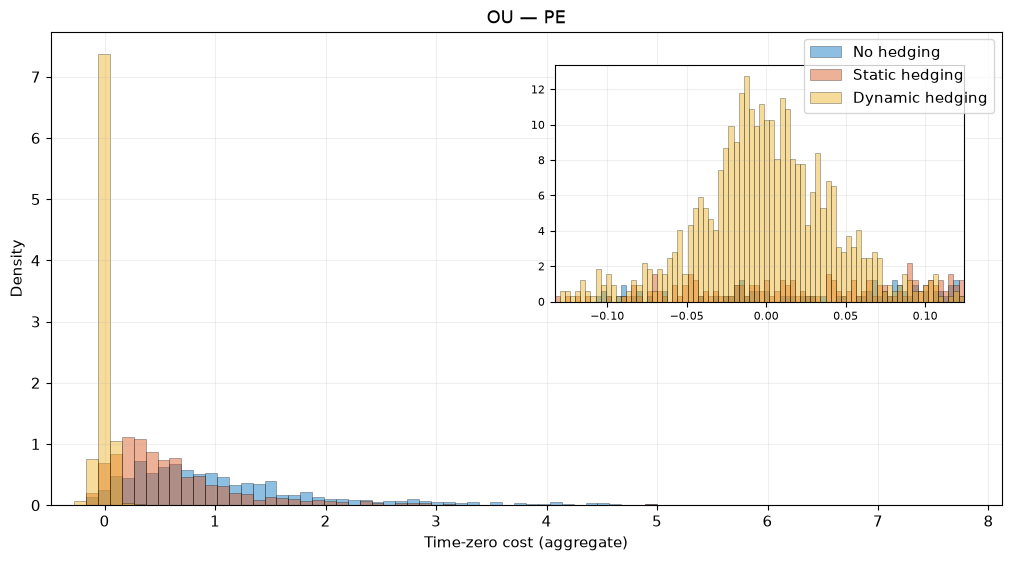

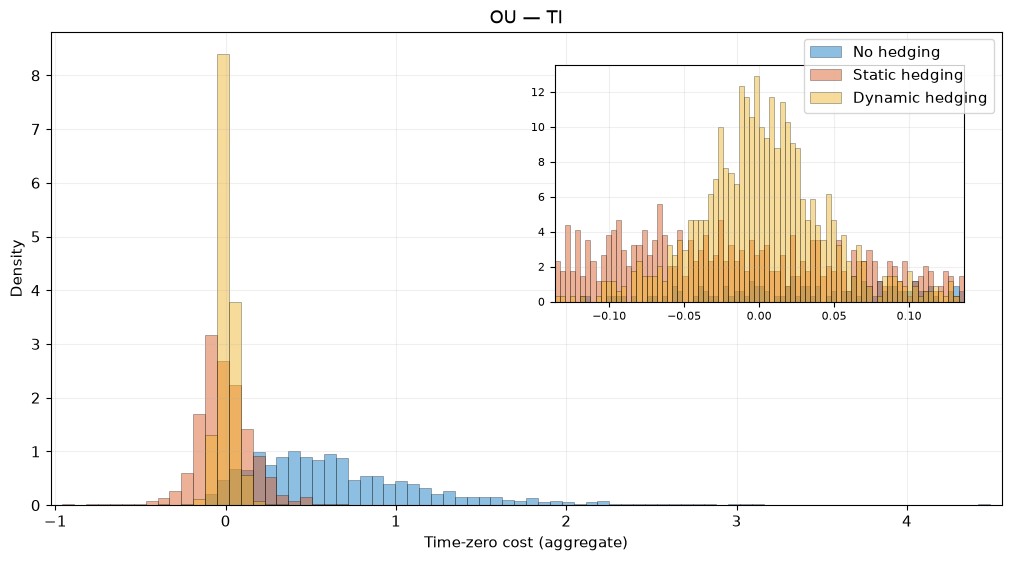

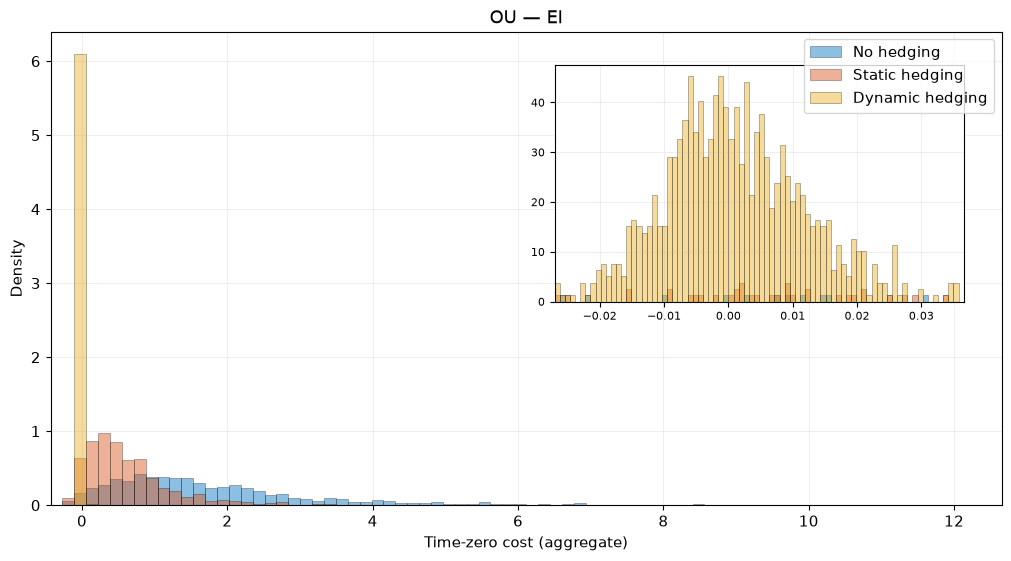

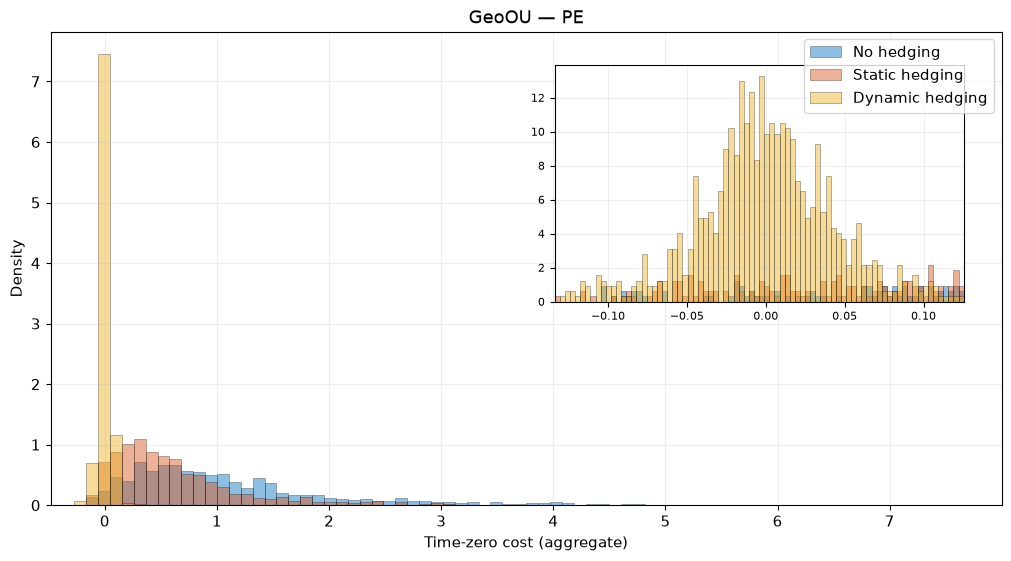

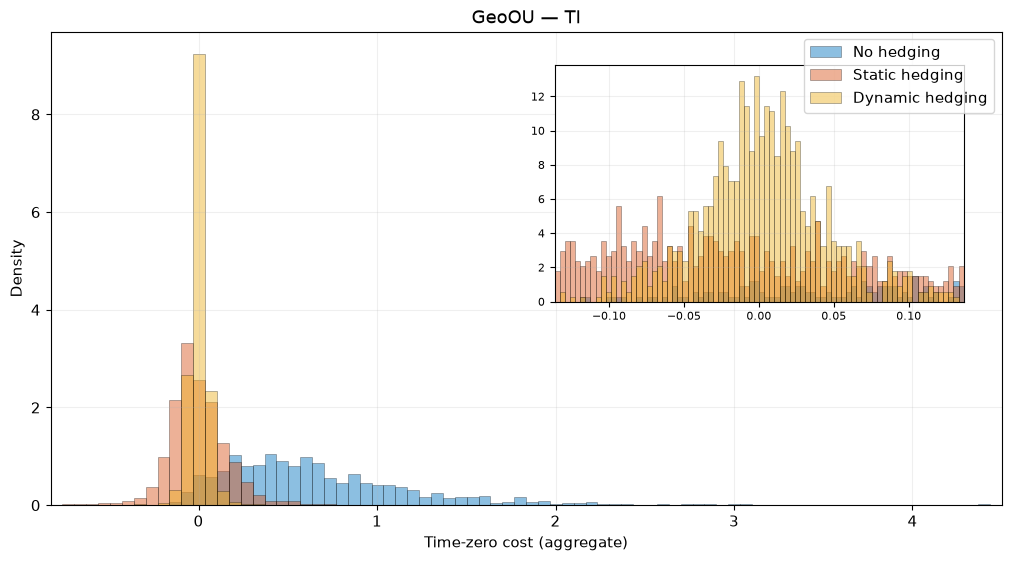

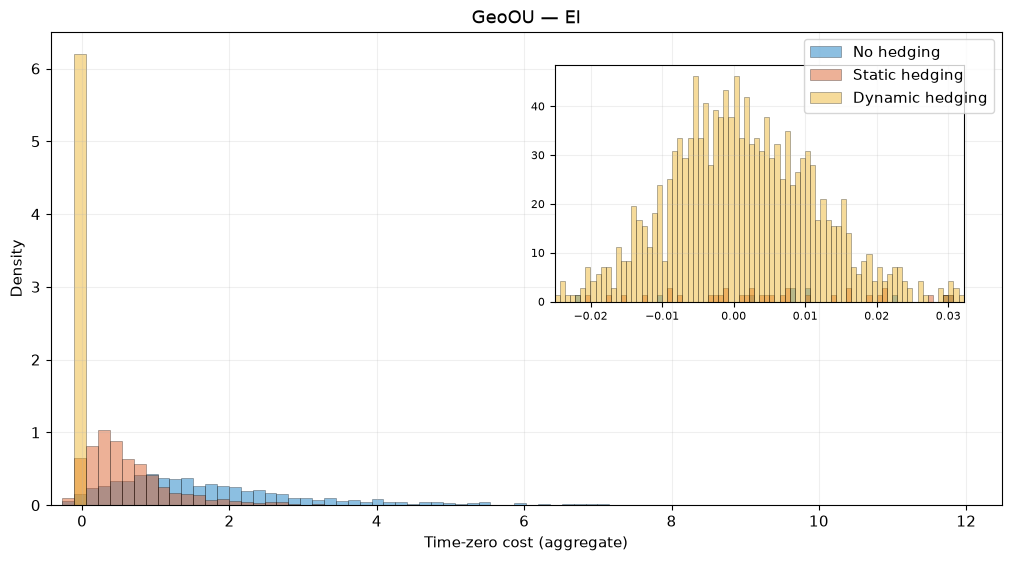

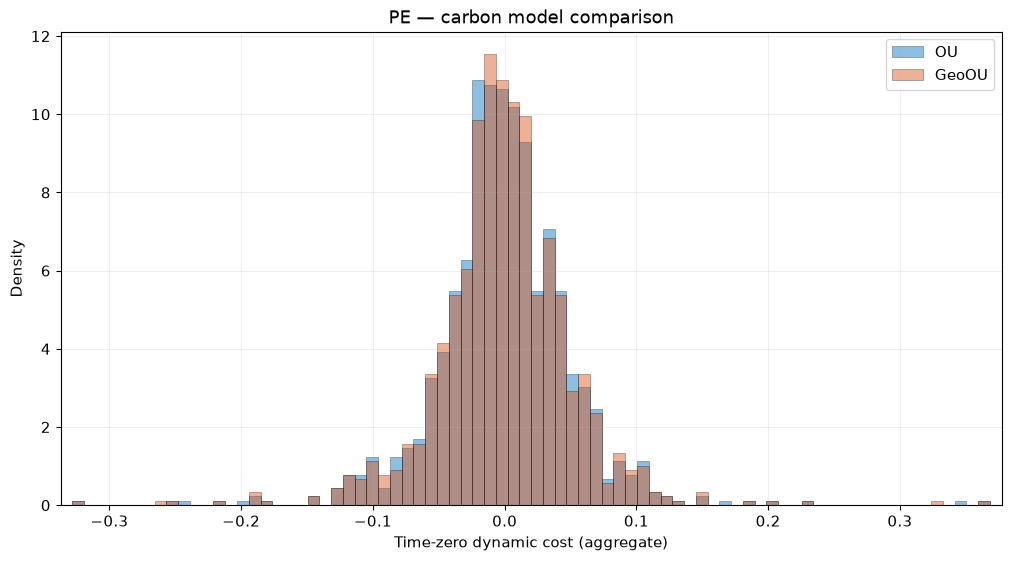

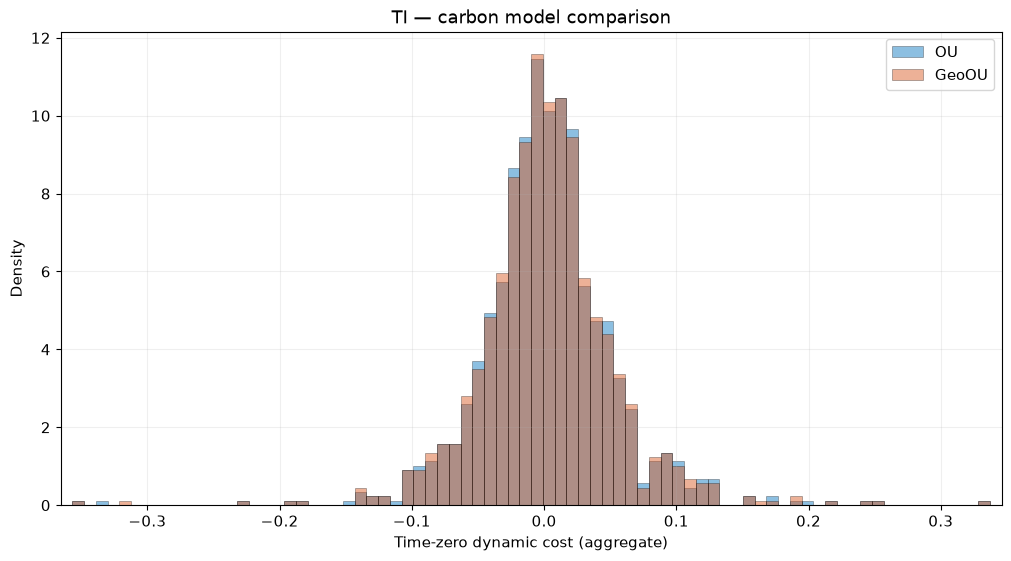

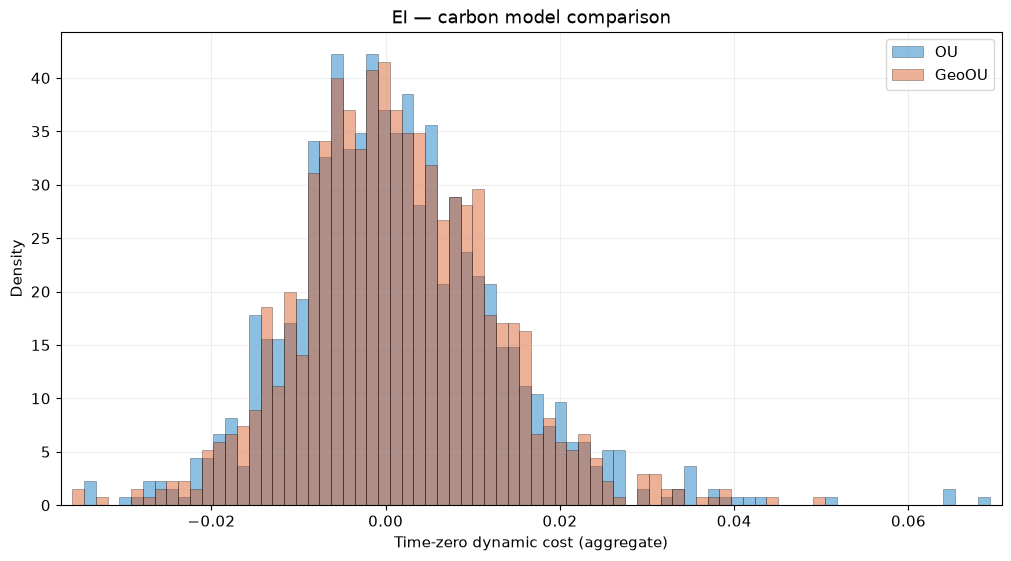

Figures: /home/edoardolombardo/Documents/codes/CarbonFund_UL/results/ou_geoou_hedging/T20_ou_geoou_02/figures


In [27]:
figure_directory = RUN_DIRECTORY / 'figures'

def finish_figure(fig, stem):
    if SAVE_FIGURES and analysis['figure_formats']:
        figure_directory.mkdir(parents=True, exist_ok=True)
        for extension in analysis['figure_formats']:
            fig.savefig(figure_directory / f'{stem}.{extension}', dpi=analysis['dpi'], bbox_inches='tight')
    if SHOW_FIGURES:
        display(fig)
    plt.close(fig)

def plotting_limits(series, quantiles):
    bounds = []
    for values, q in zip(series, quantiles):
        if len(q) != 2 or not 0 <= q[0] < q[1] <= 1:
            raise ValueError('Plot quantiles must satisfy 0 <= low < high <= 1.')
        bounds.append(np.quantile(values, q))
    lo = float(min(b[0] for b in bounds))
    hi = float(max(b[1] for b in bounds))
    padding = (hi-lo) * plot_settings['range_padding_fraction']
    if hi <= lo:
        padding = max(1.0, abs(lo)) * plot_settings['zero_width_fallback_fraction']
    return lo-padding, hi+padding

def density_histogram(ax, values, edges, label, color):
    counts, _ = np.histogram(values, bins=edges)
    heights = counts / (len(values) * np.diff(edges))
    ax.bar(edges[:-1], heights, width=np.diff(edges), align='edge', label=label,
           color=color, alpha=plot_settings['histogram_alpha'],
           edgecolor=plot_settings['edge_color'], linewidth=plot_settings['edge_linewidth'])

if SAVE_FIGURES:
    figure_directory.mkdir(parents=True, exist_ok=True)
    for extension in analysis['figure_formats']:
        carbon_figure.savefig(figure_directory / f'carbon_moments.{extension}', dpi=analysis['dpi'], bbox_inches='tight')

if SHOW_FIGURES or SAVE_FIGURES:
    for model, by_kind in results.items():
        for kind, result in by_kind.items():
            costs = result.costs / cost_denominator(result)
            series = list(costs.T)
            lo, hi = plotting_limits(series, [plot_settings['strategy_quantiles'][s] for s in strategies])
            edges = np.linspace(lo, hi, plot_settings['density_bins'] + 1)
            fig, ax = plt.subplots(figsize=plot_settings['cost_figure_size'], constrained_layout=True)
            for i, strategy in enumerate(strategies):
                density_histogram(ax, series[i], edges, plot_settings['strategy_labels'][strategy],
                                  plot_settings['strategy_colors'][strategy])
            ax.set(xlim=(lo, hi), ylim=(0, None), xlabel=f'Time-zero cost ({analysis["normalization"]})', ylabel='Density')
            if plot_settings['show_titles']:
                ax.set_title(f'{model} — {kind}')
            ax.grid(alpha=plot_settings['grid_alpha'])
            ax.legend(loc=plot_settings['legend_location'])
            if plot_settings['show_zoom']:
                zlo, zhi = plotting_limits([series[2]], [plot_settings['zoom_quantiles']])
                inset = ax.inset_axes(plot_settings['zoom_position'])
                zoom_edges = np.linspace(zlo, zhi, plot_settings['density_bins'] + 1)
                for i, strategy in enumerate(strategies):
                    density_histogram(inset, series[i], zoom_edges, plot_settings['strategy_labels'][strategy],
                                      plot_settings['strategy_colors'][strategy])
                inset.set(xlim=(zlo, zhi), ylim=(0, None))
                inset.tick_params(labelsize=max(6, plot_settings['font_size']-3))
                inset.grid(alpha=plot_settings['grid_alpha'])
            finish_figure(fig, f'{model}_{kind}_strategies')

    for kind in CONTRACT_TYPES:
        series = [results[model][kind].costs[:, 2] / cost_denominator(results[model][kind]) for model in models_to_run]
        lo, hi = plotting_limits(series, [plot_settings['dynamic_model_quantiles']] * len(series))
        edges = np.linspace(lo, hi, plot_settings['density_bins'] + 1)
        fig, ax = plt.subplots(figsize=plot_settings['cost_figure_size'], constrained_layout=True)
        for model, values in zip(models_to_run, series):
            density_histogram(ax, values, edges, model, plot_settings['model_colors'][model])
        ax.set(xlim=(lo, hi), ylim=(0, None), xlabel=f'Time-zero dynamic cost ({analysis["normalization"]})', ylabel='Density')
        if plot_settings['show_titles']:
            ax.set_title(f'{kind} — carbon model comparison')
        ax.legend(loc=plot_settings['legend_location'])
        ax.grid(alpha=plot_settings['grid_alpha'])
        finish_figure(fig, f'{kind}_dynamic_model_comparison')
print('Figures:', figure_directory)


**Saved files and later analysis.** Each `MODEL/CONTRACT/hedging.csv` contains
one row per outer scenario with `scenario_id`, `no_hedge`, `static_hedge`,
`dynamic_hedge`, `claims_pv`, both trading-gain PV columns, `fund_terminal`
and `initial_price`. These are raw aggregate amounts and can be read directly
in MATLAB, R or another program. Carbon and fund paths at intermediate dates
are **not** saved by this runner; terminal fund values are saved.

The root CSVs contain model parameters, continuous carbon diagnostics,
compact strategy tables, complete cost summaries, paired comparisons,
initial valuations, timing and accounting checks. `config.json` and
`metadata.json` in each run preserve the exact simulation settings. The
current analysis choices are recorded separately in `analysis.json` and
`notebook_analysis.json`; reloading does not change the original raw data.

For an existing run, set `RUN_SIMULATIONS=False`, retain the same design,
and run all cells. To test convergence, use a new `RUN_NAME`, increase one
budget at a time and keep the remaining inputs and seeds fixed. First
examine the outer grid, then initial and revaluation accuracy. A finite-grid
dynamic hedge need not have an exactly zero estimated mean.


In [28]:
print('Experiment directory:', RUN_DIRECTORY)
for model in models_to_run:
    for kind in CONTRACT_TYPES:
        print(f'Raw {model}/{kind}:', RUN_DIRECTORY / model / kind / 'hedging.csv')
print('\nRoot CSV files:')
for path in sorted(RUN_DIRECTORY.glob('*.csv')):
    print(' ', path.name)
print('\nExact design:', RUN_DIRECTORY / 'experiment_design.json')
print('Calibration:', RUN_DIRECTORY / 'calibration.json')
print('Current analysis:', RUN_DIRECTORY / 'notebook_analysis.json')
print('Figures:', figure_directory)


Experiment directory: /home/edoardolombardo/Documents/codes/CarbonFund_UL/results/ou_geoou_hedging/T20_ou_geoou_02
Raw OU/PE: /home/edoardolombardo/Documents/codes/CarbonFund_UL/results/ou_geoou_hedging/T20_ou_geoou_02/OU/PE/hedging.csv
Raw OU/TI: /home/edoardolombardo/Documents/codes/CarbonFund_UL/results/ou_geoou_hedging/T20_ou_geoou_02/OU/TI/hedging.csv
Raw OU/EI: /home/edoardolombardo/Documents/codes/CarbonFund_UL/results/ou_geoou_hedging/T20_ou_geoou_02/OU/EI/hedging.csv
Raw GeoOU/PE: /home/edoardolombardo/Documents/codes/CarbonFund_UL/results/ou_geoou_hedging/T20_ou_geoou_02/GeoOU/PE/hedging.csv
Raw GeoOU/TI: /home/edoardolombardo/Documents/codes/CarbonFund_UL/results/ou_geoou_hedging/T20_ou_geoou_02/GeoOU/TI/hedging.csv
Raw GeoOU/EI: /home/edoardolombardo/Documents/codes/CarbonFund_UL/results/ou_geoou_hedging/T20_ou_geoou_02/GeoOU/EI/hedging.csv

Root CSV files:
  accounting_checks.csv
  carbon_curve_diagnostics.csv
  carbon_integral_moments.csv
  carbon_marginal_moments.csv
  c